# 9주차 실습 1 — 트리의 앙상블과 Iris 응용예제

**작성자: 이영언**

여러 개의 결정트리를 결합하는 랜덤 포레스트, 엑스트라 트리, 그레이디언트 부스팅, 히스토그램 기반 부스팅을 실습하고 마지막에 Iris 품종 분류 문제에 적용한다.

## 1. 데이터 준비

와인 데이터의 `alcohol`, `sugar`, `pH`를 입력 특성으로 사용하고 `class`를 정답으로 사용한다. 훈련 세트와 테스트 세트를 80:20으로 분리한다.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier,
                              HistGradientBoostingClassifier)
from sklearn.inspection import permutation_importance

# 교재에서 제공하는 와인 데이터를 읽습니다.
wine = pd.read_csv('https://bit.ly/wine-date')
data = wine[['alcohol', 'sugar', 'pH']].to_numpy()
target = wine['class'].to_numpy()

train_input, test_input, train_target, test_target = train_test_split(
    data, target, test_size=0.2, random_state=42, stratify=target)

print('전체 데이터:', data.shape)
print('훈련 세트:', train_input.shape, '테스트 세트:', test_input.shape)
display(wine.head())

전체 데이터: (6497, 3)
훈련 세트: (5197, 3) 테스트 세트: (1300, 3)
 alcohol  sugar   pH  class
     9.4    1.9 3.51    0.0
     9.8    2.6 3.20    0.0
     9.8    2.3 3.26    0.0
     9.8    1.9 3.16    0.0
     9.4    1.9 3.51    0.0


## 2. 랜덤 포레스트(Random Forest)

훈련 데이터를 무작위로 복원 추출해 여러 결정트리를 만들고, 분류에서는 각 트리의 예측을 투표하여 최종 답을 정한다. 개별 트리보다 과대적합을 줄이고 안정적인 성능을 얻을 수 있다.

In [2]:
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
scores = cross_validate(rf, train_input, train_target,
                        return_train_score=True, n_jobs=1)
print('교차검증 훈련 점수:', np.mean(scores['train_score']))
print('교차검증 검증 점수:', np.mean(scores['test_score']))

rf.fit(train_input, train_target)
print('테스트 점수:', rf.score(test_input, test_target))
print('특성 중요도 [alcohol, sugar, pH]:', rf.feature_importances_)

교차검증 훈련 점수: 0.9981720130385032
교차검증 검증 점수: 0.8920496779447694
테스트 점수: 0.8907692307692308
특성 중요도 [alcohol, sugar, pH]: [0.23297476 0.50010682 0.26691842]


### OOB(Out Of Bag) 평가

각 트리의 부트스트랩 표본에 뽑히지 않은 데이터를 OOB 샘플이라고 한다. 이 샘플을 검증용으로 사용하면 별도의 검증 세트 없이 일반화 성능을 확인할 수 있다.

In [3]:
rf_oob = RandomForestClassifier(n_estimators=200, oob_score=True,
                                n_jobs=-1, random_state=42)
rf_oob.fit(train_input, train_target)
print('OOB 점수:', rf_oob.oob_score_)

OOB 점수: 0.8976332499518953


## 3. 엑스트라 트리(Extra Trees)

부트스트랩 표본을 기본적으로 사용하지 않고 전체 훈련 데이터를 사용한다. 각 노드에서 특성과 분할 기준을 더 무작위로 선택하므로 편향은 조금 커질 수 있지만 분산을 줄이고 학습 속도가 빠르다.

In [4]:
et = ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=42)
scores = cross_validate(et, train_input, train_target,
                        return_train_score=True, n_jobs=1)
print('교차검증 훈련 점수:', np.mean(scores['train_score']))
print('교차검증 검증 점수:', np.mean(scores['test_score']))

et.fit(train_input, train_target)
print('테스트 점수:', et.score(test_input, test_target))
print('특성 중요도:', et.feature_importances_)

교차검증 훈련 점수: 0.9981720130385032
교차검증 검증 점수: 0.8907027837417635
테스트 점수: 0.8815384615384615
특성 중요도: [0.2021846  0.51744772 0.28036767]


## 4. 그레이디언트 부스팅(Gradient Boosting)

얕은 결정트리를 순서대로 추가하면서 앞 모델이 틀린 부분을 다음 트리가 보완한다. `learning_rate`가 작을수록 천천히 학습하며 보통 더 많은 트리가 필요하다.

In [5]:
gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1,
                                max_depth=2, random_state=42)
scores = cross_validate(gb, train_input, train_target,
                        return_train_score=True, n_jobs=1)
print('교차검증 훈련 점수:', np.mean(scores['train_score']))
print('교차검증 검증 점수:', np.mean(scores['test_score']))

gb.fit(train_input, train_target)
print('테스트 점수:', gb.score(test_input, test_target))
print('특성 중요도:', gb.feature_importances_)

교차검증 훈련 점수: 0.8899844522408872
교차검증 검증 점수: 0.8693453394536167
테스트 점수: 0.8561538461538462
특성 중요도: [0.12118209 0.73529337 0.14352454]


## 5. 히스토그램 기반 그레이디언트 부스팅

연속적인 특성값을 구간으로 나누어 히스토그램으로 처리하기 때문에 일반 그레이디언트 부스팅보다 대용량 데이터에서 빠르다.

In [6]:
hgb = HistGradientBoostingClassifier(max_iter=200, random_state=42)
scores = cross_validate(hgb, train_input, train_target,
                        return_train_score=True, n_jobs=1)
print('교차검증 훈련 점수:', np.mean(scores['train_score']))
print('교차검증 검증 점수:', np.mean(scores['test_score']))

hgb.fit(train_input, train_target)
print('테스트 점수:', hgb.score(test_input, test_target))

교차검증 훈련 점수: 0.9612759321684028
교차검증 검증 점수: 0.882235507514622
테스트 점수: 0.8807692307692307


## 6. 순열 중요도(Permutation Importance)

특정 특성의 값을 무작위로 섞었을 때 모델 점수가 얼마나 감소하는지 측정한다. 점수가 크게 떨어지는 특성일수록 예측에 중요한 특성이다.

feature  importance_mean  importance_std
  sugar         0.202615        0.014956
alcohol         0.056923        0.004961
     pH         0.054154        0.007052


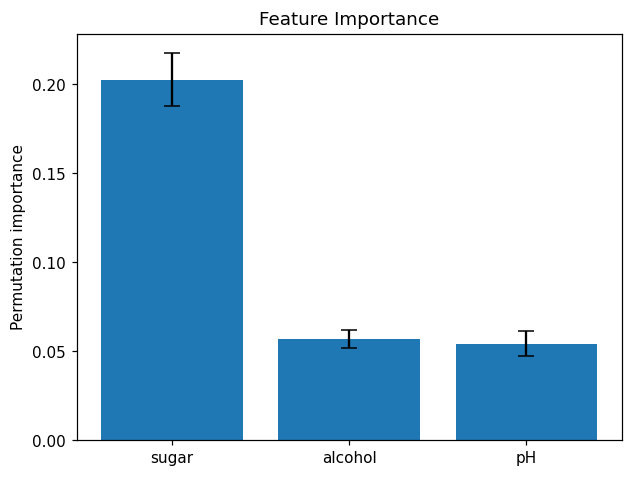

In [7]:
result = permutation_importance(
    hgb, test_input, test_target, n_repeats=10, random_state=42, n_jobs=1)

importance = pd.DataFrame({
    'feature': ['alcohol', 'sugar', 'pH'],
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values('importance_mean', ascending=False)
display(importance)

plt.bar(importance['feature'], importance['importance_mean'],
        yerr=importance['importance_std'], capsize=5)
plt.ylabel('Permutation importance')
plt.title('Feature Importance')
plt.show()

## 7. XGBoost와 LightGBM

두 모델 모두 효율적인 그레이디언트 부스팅 라이브러리이다. XGBoost는 안정성과 규제 기능이 강하고, LightGBM은 리프 중심으로 트리를 성장시켜 대용량 데이터에서 빠른 편이다.

In [8]:
# 코랩에 라이브러리가 없을 경우를 대비한 설치 명령입니다.
!pip -q install xgboost lightgbm

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                    random_state=42, eval_metric='logloss', n_jobs=1)
xgb.fit(train_input, train_target)

lgb = LGBMClassifier(n_estimators=200, learning_rate=0.1,
                     random_state=42, verbose=-1, n_jobs=1)
lgb.fit(train_input, train_target)

print('XGBoost 테스트 점수:', xgb.score(test_input, test_target))
print('LightGBM 테스트 점수:', lgb.score(test_input, test_target))

XGBoost 테스트 점수: 0.8638461538461538
LightGBM 테스트 점수: 0.8823076923076923


# 응용예제 — Iris 품종 예측

`sepal_length`, `sepal_width`, `petal_length`, `petal_width` 네 특성으로 Iris의 세 품종을 예측한다.

### 수행 과정

1. Iris 데이터를 입력 특성과 정답으로 분리한다.
2. 품종 비율이 유지되도록 훈련/테스트 세트를 분리한다.
3. 결정트리, 랜덤 포레스트, 그레이디언트 부스팅을 같은 데이터로 학습한다.
4. 테스트 정확도와 혼동행렬을 비교한다.

            model  train_accuracy  test_accuracy
    Decision Tree        0.983333       0.966667
    Random Forest        1.000000       0.900000
Gradient Boosting        1.000000       0.966667


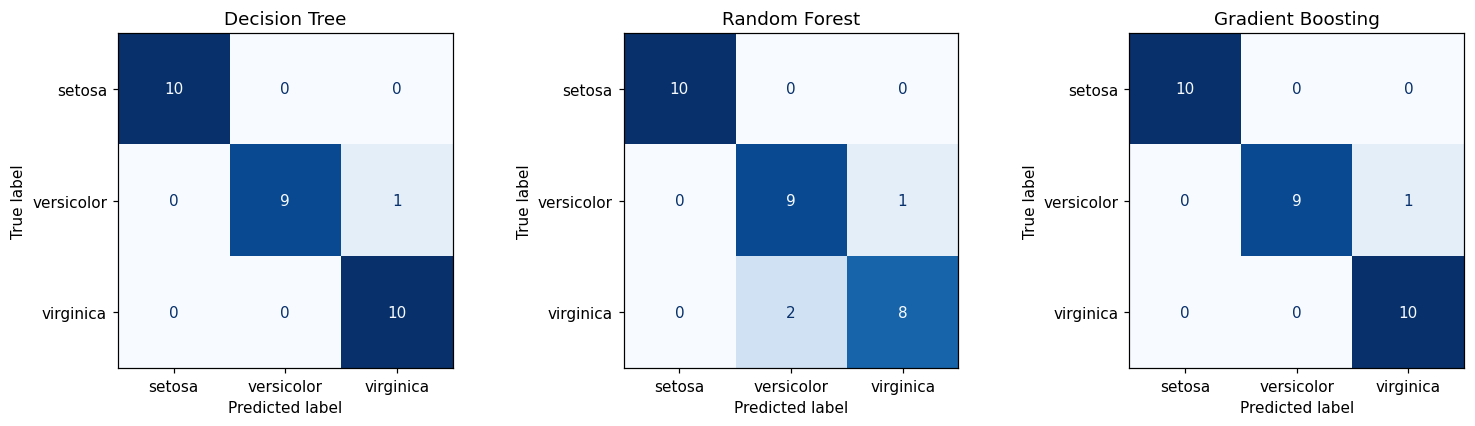

In [9]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

iris_models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, random_state=42)
}

rows = []
predictions = {}
for name, model in iris_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        'model': name,
        'train_accuracy': model.score(X_train, y_train),
        'test_accuracy': accuracy_score(y_test, pred)
    })

comparison = pd.DataFrame(rows)
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=iris.target_names,
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

가장 높은 테스트 정확도 모델: Decision Tree
최고 테스트 정확도: 0.9666666666666667


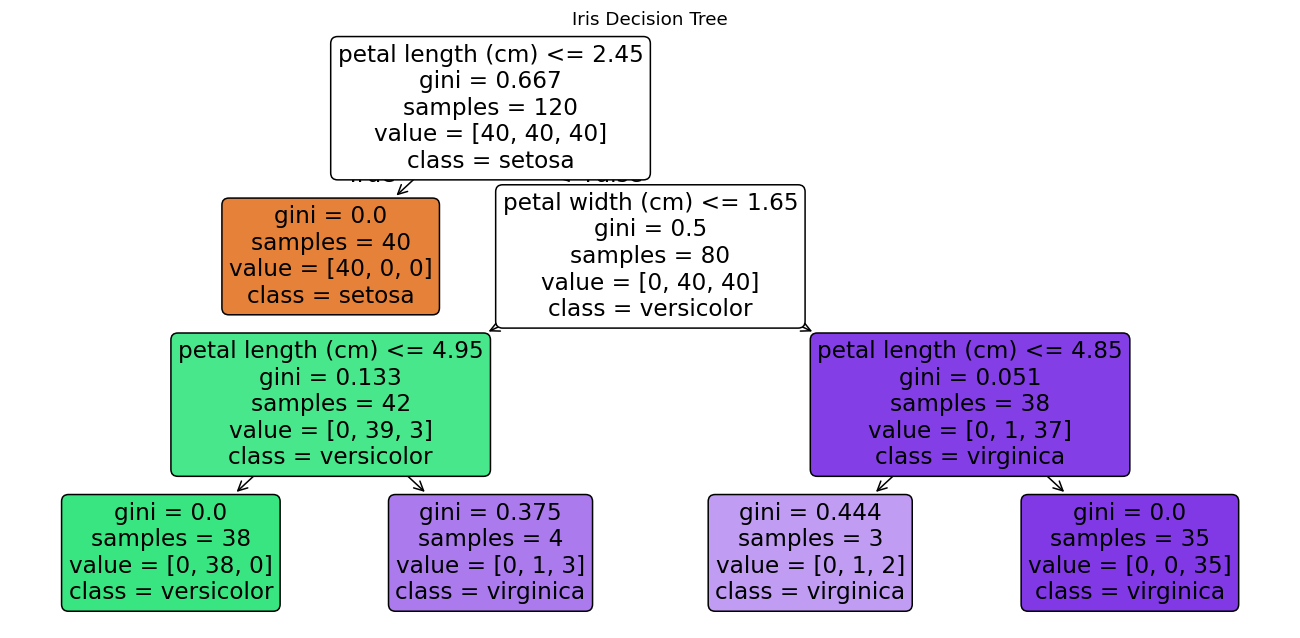

In [10]:
# 결정트리가 실제로 어떤 규칙으로 분류했는지 시각화합니다.
dt = iris_models['Decision Tree']
plt.figure(figsize=(15, 7))
plot_tree(dt, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True)
plt.title('Iris Decision Tree')
plt.show()

best_row = comparison.loc[comparison['test_accuracy'].idxmax()]
print('가장 높은 테스트 정확도 모델:', best_row['model'])
print('최고 테스트 정확도:', best_row['test_accuracy'])

## 응용예제 결과 해석

- 결정트리는 분류 규칙을 그림으로 확인할 수 있어 설명력이 높다.
- 랜덤 포레스트는 여러 트리의 결과를 평균내어 단일 트리보다 안정적이다.
- 그레이디언트 부스팅은 앞 모델의 오차를 순차적으로 보완한다.
- Iris 데이터에서는 꽃잎 길이와 꽃잎 너비가 품종 분류에 특히 큰 역할을 하며, 세 모델 모두 높은 정확도를 보인다.

## AI 활용 기록

실습 코드의 구조화, 오류 점검, 결과표와 해석 문장 작성에 생성형 AI의 도움을 받았으며, 모든 셀을 실제 실행하여 출력값을 확인하였다.